# Notebook 03 — MobileNetV2 Eye-State Classification


## 1. Imports 

In [1]:
import os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 2. Find project root and load manifests

In [2]:
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find project root containing data/processed. "
        "Open this notebook from the project folder or its notebooks folder."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models" / "eye_state"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "training" / "mobilenetv2_eye"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_manifest = pd.read_csv(DATA_DIR / "train_manifest.csv")
val_manifest = pd.read_csv(DATA_DIR / "validation_manifest.csv")
test_manifest = pd.read_csv(DATA_DIR / "test_manifest.csv")

print("Project root:", PROJECT_ROOT)
print("Manifest columns:", train_manifest.columns.tolist())
print("Manifest sizes:", len(train_manifest), len(val_manifest), len(test_manifest))

Project root: D:\driver drowsiness detection final
Manifest columns: ['path', 'relative_path', 'class_name', 'split_source', 'split']
Manifest sizes: 1973 494 433


## 3. Prepare Closed/Open manifests

In [3]:
CLASS_TO_INDEX = {"Closed": 0, "Open": 1}
required = {"path", "class_name"}

for split_name, frame in [
    ("train", train_manifest), ("validation", val_manifest), ("test", test_manifest)
]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{split_name} manifest missing columns: {sorted(missing)}")

def resolve_path(value):
    p = Path(str(value))
    if p.is_absolute() and p.exists():
        return str(p.resolve())
    candidates = [
        PROJECT_ROOT / p,
        PROJECT_ROOT / "data" / "raw" / p,
        PROJECT_ROOT / "data" / "raw" / "dataset_new" / p,
    ]
    for candidate in candidates:
        if candidate.exists():
            return str(candidate.resolve())
    raise FileNotFoundError(f"Image path not found: {value}")

def prepare_eye_manifest(frame, split_name):
    df = frame[frame["class_name"].isin(CLASS_TO_INDEX)].copy()
    if df.empty:
        raise ValueError(f"No Closed/Open images found in {split_name} manifest.")
    df["label"] = df["class_name"].map(CLASS_TO_INDEX).astype("int32")
    df["path"] = df["path"].apply(resolve_path)
    return df.reset_index(drop=True)

train_eye = prepare_eye_manifest(train_manifest, "train")
val_eye = prepare_eye_manifest(val_manifest, "validation")
test_eye = prepare_eye_manifest(test_manifest, "test")

for name, frame in [("Train", train_eye), ("Validation", val_eye), ("Test", test_eye)]:
    print(f"\n{name}: {len(frame)} images")
    print(frame["class_name"].value_counts().to_dict())


Train: 987 images
{'Closed': 494, 'Open': 493}

Validation: 247 images
{'Open': 124, 'Closed': 123}

Test: 218 images
{'Closed': 109, 'Open': 109}


## 4. Build datasets with MobileNetV2 preprocessing

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Only training images are augmented. Validation/test are unchanged.
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.03, fill_mode="reflect", seed=SEED),
], name="eye_augmentation")

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    # MobileNetV2 preprocess_input expects RGB values in [0,255],
    # and scales them to approximately [-1,1].
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    label = tf.cast(label, tf.float32)
    return image, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["path"].astype(str).to_numpy(),
        frame["label"].astype("float32").to_numpy()
    ))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(
        lambda path, label: load_image(path, label),
        num_parallel_calls=AUTOTUNE
    )

    if training:
        
        ds = ds.map(
            lambda image, label: (augmentation(image, training=True), label),
            num_parallel_calls=AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_eye, training=True)
train_eval_ds = make_dataset(train_eye, training=False)
val_ds = make_dataset(val_eye, training=False)
test_ds = make_dataset(test_eye, training=False)

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Preprocessed pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
    print("Label counts:", np.unique(labels.numpy(), return_counts=True))

Image batch shape: (32, 224, 224, 3)
Preprocessed pixel range: -1.0 to 0.999890148639679
Label counts: (array([0., 1.], dtype=float32), array([16, 16], dtype=int64))


## 5. Build MobileNetV2 with pretrained ImageNet weights

In [ ]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3), name="preprocessed_eye_image")
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.20)(x)
outputs = layers.Dense(1, activation="sigmoid", name="open_probability")(x)

model = keras.Model(inputs, outputs, name="mobilenetv2_eye")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)
model.summary()

Model: "mobilenetv2_eye"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocessed_eye_image          │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ open_probability (Dense)        │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Train the classifier head

In [6]:
MODEL_PATH = MODEL_DIR / "mobilenetv2_eye.keras"
LOG_PATH = OUTPUT_DIR / "training_log_head.csv"
HISTORY_PATH = OUTPUT_DIR / "training_history_head.csv"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(MODEL_PATH), monitor="val_loss", mode="min",
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", mode="min", patience=5,
        min_delta=1e-4, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", mode="min", factor=0.2,
        patience=2, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.CSVLogger(str(LOG_PATH)),
]

EPOCHS_HEAD = 15
start = time.time()
history_head = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_HEAD, callbacks=callbacks, verbose=1
)
head_minutes = (time.time() - start) / 60
pd.DataFrame(history_head.history).to_csv(HISTORY_PATH, index=False)
print(f"Head training time: {head_minutes:.2f} minutes")

Epoch 1/15


d:\driver drowsiness detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 578ms/step - accuracy: 0.9311 - auc: 0.9851 - loss: 0.1628 - precision: 0.9328 - recall: 0.9290
Epoch 1: val_loss improved from None to 0.02268, saving model to D:\driver drowsiness detection final\models\eye_state\mobilenetv2_eye.keras

Epoch 1: finished saving model to D:\driver drowsiness detection final\models\eye_state\mobilenetv2_eye.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 32s 830ms/step - accuracy: 0.9311 - auc: 0.9851 - loss: 0.1628 - precision: 0.9328 - recall: 0.9290 - val_accuracy: 0.9879 - val_auc: 0.9997 - val_loss: 0.0227 - val_precision: 0.9840 - val_recall: 0.9919 - learning_rate: 0.0010
Epoch 2/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 580ms/step - accuracy: 0.9889 - auc: 0.9982 - loss: 0.0357 - precision: 0.9939 - recall: 0.9838
Epoch 2: val_loss did not improve from 0.02268
31/31 ━━━━━━━━━━━━━━━━━━━━ 23s 726ms/step - accuracy: 0.9889 - auc: 0.9982 - loss: 0.0357 - precision: 0.9939 - recall: 0.9838 - val_accuracy: 0.9879 - val_auc: 0.9999 - val_loss: 0.

## 7. Plot head-training curves

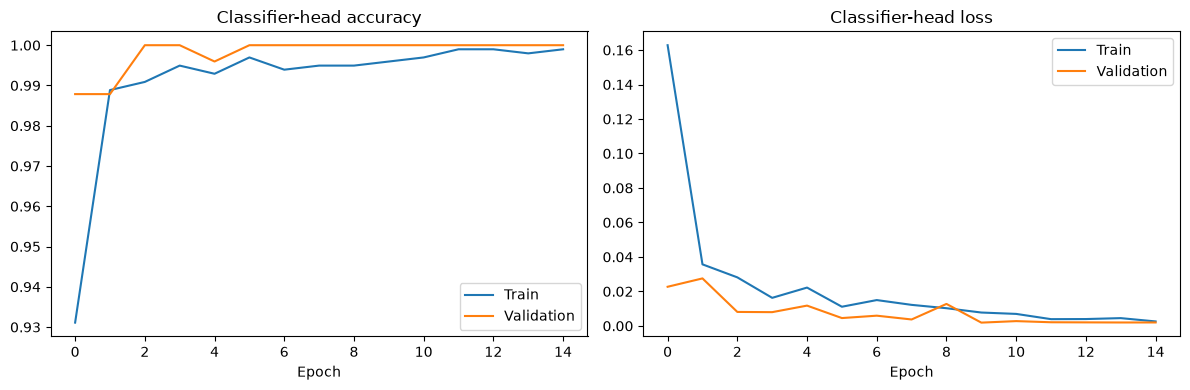

In [7]:
head_df = pd.DataFrame(history_head.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(head_df["accuracy"], label="Train")
axes[0].plot(head_df["val_accuracy"], label="Validation")
axes[0].set_title("Classifier-head accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(head_df["loss"], label="Train")
axes[1].plot(head_df["val_loss"], label="Validation")
axes[1].set_title("Classifier-head loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Optional fine-tuning of the top backbone layers

In [ ]:
FINE_TUNE = True

if FINE_TUNE:
    best_head = keras.models.load_model(MODEL_PATH)
    # Retrieve the base model by its known name.
    fine_base = best_head.get_layer("mobilenetv2_1.00_224")
    fine_base.trainable = True

    # Fine-tune only the top portion of the backbone.
    fine_tune_at = max(0, len(fine_base.layers) - 30)
    for layer in fine_base.layers[:fine_tune_at]:
        layer.trainable = False
    for layer in fine_base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    best_head.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )

    FT_MODEL_PATH = MODEL_DIR / "mobilenetv2_eye_finetuned.keras"
    ft_callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(FT_MODEL_PATH), monitor="val_loss", mode="min",
            save_best_only=True, verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=4,
            min_delta=1e-4, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", mode="min", factor=0.2,
            patience=2, min_lr=1e-7, verbose=1
        ),
        keras.callbacks.CSVLogger(str(OUTPUT_DIR / "training_log_finetune.csv")),
    ]

    ft_start = time.time()
    history_ft = best_head.fit(
        train_ds, validation_data=val_ds, epochs=10,
        callbacks=ft_callbacks, verbose=1
    )
    ft_minutes = (time.time() - ft_start) / 60
    pd.DataFrame(history_ft.history).to_csv(
        OUTPUT_DIR / "training_history_finetune.csv", index=False
    )
    print(f"Fine-tuning time: {ft_minutes:.2f} minutes")
    FINAL_MODEL_PATH = FT_MODEL_PATH
else:
    ft_minutes = 0.0
    FINAL_MODEL_PATH = MODEL_PATH

print("Final candidate model:", FINAL_MODEL_PATH)

Epoch 1/10


d:\driver drowsiness detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 680ms/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0046 - precision: 1.0000 - recall: 0.9980
Epoch 1: val_loss improved from None to 0.00307, saving model to D:\driver drowsiness detection final\models\eye_state\mobilenetv2_eye_finetuned.keras

Epoch 1: finished saving model to D:\driver drowsiness detection final\models\eye_state\mobilenetv2_eye_finetuned.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 38s 922ms/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0046 - precision: 1.0000 - recall: 0.9980 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0031 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 872ms/step - accuracy: 0.9970 - auc: 1.0000 - loss: 0.0044 - precision: 0.9980 - recall: 0.9959
Epoch 2: val_loss improved from 0.00307 to 0.00152, saving model to D:\driver drowsiness detection final\models\eye_state\mobilenetv2_eye_finetuned.keras

Epoch 2: finished saving model to D:\driver drowsi

## 9. Evaluate the selected checkpoint on the test set

accuracy                 0.995413
precision_open           0.990909
recall_open              1.000000
f1_open                  0.995434
roc_auc                  1.000000
head_training_minutes    6.925155
fine_tuning_minutes      5.919334

Classification report:
              precision    recall  f1-score   support

      Closed       1.00      0.99      1.00       109
        Open       0.99      1.00      1.00       109

    accuracy                           1.00       218
   macro avg       1.00      1.00      1.00       218
weighted avg       1.00      1.00      1.00       218



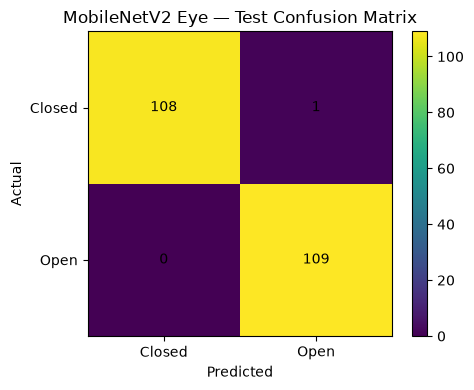

Saved outputs to: D:\driver drowsiness detection final\outputs\training\mobilenetv2_eye


In [9]:
final_model = keras.models.load_model(FINAL_MODEL_PATH)

test_y = test_eye["label"].to_numpy().astype(int)
test_prob = final_model.predict(test_ds, verbose=0).ravel()
test_pred = (test_prob >= 0.5).astype(int)

metrics = {
    "accuracy": accuracy_score(test_y, test_pred),
    "precision_open": precision_score(test_y, test_pred, zero_division=0),
    "recall_open": recall_score(test_y, test_pred, zero_division=0),
    "f1_open": f1_score(test_y, test_pred, zero_division=0),
    "roc_auc": roc_auc_score(test_y, test_prob),
    "head_training_minutes": head_minutes,
    "fine_tuning_minutes": ft_minutes,
}
print(pd.Series(metrics).to_string())
print("\nClassification report:")
print(classification_report(
    test_y, test_pred, labels=[0, 1],
    target_names=["Closed", "Open"], zero_division=0
))

cm = confusion_matrix(test_y, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Closed", "Open"])
ax.set_yticks([0, 1], labels=["Closed", "Open"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("MobileNetV2 Eye — Test Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
pd.DataFrame({
    "path": test_eye["path"],
    "class_name": test_eye["class_name"],
    "true_label": test_y,
    "probability_open": test_prob,
    "predicted_label": test_pred,
}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Saved outputs to:", OUTPUT_DIR)

## 10. Probability diagnostics and next steps

Probability range: 1.5314359780305153e-09 to 1.0
Mean Open probability: 0.506415069103241
Probability standard deviation: 0.4982888698577881
Predicted class counts [Closed, Open]: [108 110]


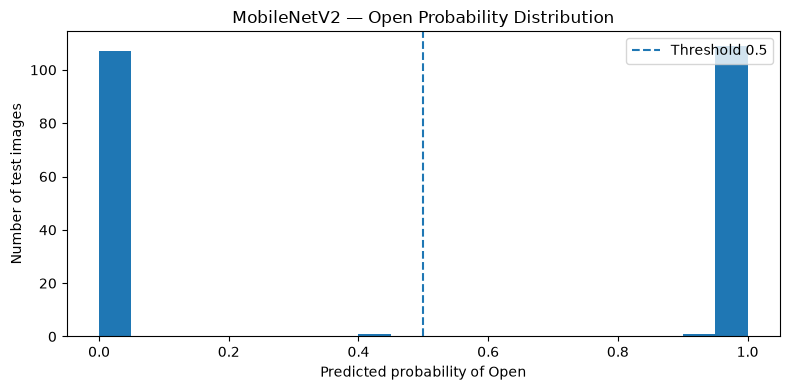

Important: evaluate the confusion matrix and class-wise recall. Do not change the decision threshold based on test data.


In [10]:
print("Probability range:", float(test_prob.min()), "to", float(test_prob.max()))
print("Mean Open probability:", float(test_prob.mean()))
print("Probability standard deviation:", float(test_prob.std()))
print("Predicted class counts [Closed, Open]:", np.bincount(test_pred, minlength=2))

plt.figure(figsize=(8, 4))
plt.hist(test_prob, bins=20)
plt.axvline(0.5, linestyle="--", label="Threshold 0.5")
plt.xlabel("Predicted probability of Open")
plt.ylabel("Number of test images")
plt.title("MobileNetV2 — Open Probability Distribution")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Important: evaluate the confusion matrix and class-wise recall. "
    "Do not change the decision threshold based on test data."
)